# Analisis Value at Risk dengan EVT Block Maxima (R)
## Saham TLKM, ISAT, dan EXCL | 2019–2025

## 1. Persiapan
### 1.1. Pustaka dan Pengaturan Grafik

Pustaka R digunakan untuk mengambil data, membuat grafik, menghitung return, dan mengestimasi VaR.

In [1]:
suppressPackageStartupMessages({
    library(quantmod)    # getSymbols, Ad, Vo, ROC
    library(evd)         # fgev, qgev, pgev, rgev
    library(extRemes)    # fevd (hanya untuk plot diagnostik)
    library(moments)     # skewness, kurtosis, jarque.test
    library(ggplot2)
    library(dplyr)
    library(tidyr)
})

options(repr.plot.width = 12, repr.plot.height = 5, digits = 7)
theme_set(theme_minimal(base_size = 12))

long_series <- function(x) {
    data <- data.frame(Tanggal = as.Date(index(x)), coredata(x), check.names = FALSE)
    data <- pivot_longer(data, -Tanggal, names_to = "Saham", values_to = "Nilai")
    mutate(data, Saham = factor(Saham, levels = SAHAM))
}

percent <- function(x) paste0(formatC(100 * x, format = "f", digits = 1), "%")

Warning message:
"package 'evd' was built under R version 4.5.3"
Warning message:
"package 'extRemes' was built under R version 4.5.3"
Warning message:
"package 'Lmoments' was built under R version 4.5.3"
Warning message:
"package 'distillery' was built under R version 4.5.2"


### 1.2. Pengaturan Analisis

Analisis menggunakan blok lima hari perdagangan, tingkat kepercayaan 95% dan 99%, serta contoh investasi Rp1 miliar per saham.

In [2]:
TICKERS <- c(TLKM = "TLKM.JK", ISAT = "ISAT.JK", EXCL = "EXCL.JK")
SAHAM <- names(TICKERS)
START_DATE <- as.Date("2019-01-01")
END_DATE <- as.Date("2026-01-01")      # argumen 'to' Yahoo bersifat eksklusif
ESTIMASI_AKHIR <- as.Date("2024-12-31")     # akhir periode estimasi
BACKTESTING_AWAL <- as.Date("2025-01-01")    # awal periode backtesting
BACKTESTING_AKHIR <- as.Date("2025-12-31")
WINDOW <- 21
BLOCK_SIZE <- 5                        # ukuran blok (5 hari bursa)
CONFIDENCE_LEVELS <- c(0.95, 0.99)
SIGNIFICANCE <- 0.05
INVESTMENT <- 1e9                      # dana investasi Rp 1 miliar
SEED <- 123
set.seed(SEED)
COLORS <- c(TLKM = "#26799c", ISAT = "#159b80", EXCL = "#c88718")

HAPUS_HARI_NOL <- TRUE
TANGGAL_DIPERTAHANKAN <- as.Date("2023-08-25")

parameter_table <- data.frame(
    Parameter = c("Periode data", "Sumber", "Basis harga", "Basis return", "Periode estimasi",
                  "Periode backtesting", "Panjang blok",
                  "Buang hari return nol di ketiga saham", "Pengecualian tanggal", "Investasi per saham"),
    Nilai = c("2019-2025", "Yahoo Finance via quantmod::getSymbols", "Adj Close", "Simple return",
              "2019-2024", "2025", paste(BLOCK_SIZE, "hari perdagangan"),
              ifelse(HAPUS_HARI_NOL, "Ya", "Tidak"),
              ifelse(HAPUS_HARI_NOL, format(TANGGAL_DIPERTAHANKAN), "—"), "Rp1.000.000.000")
)
parameter_table

Parameter,Nilai
<chr>,<chr>
Periode data,2019-2025
Sumber,Yahoo Finance via quantmod::getSymbols
Basis harga,Adj Close
Basis return,Simple return
Periode estimasi,2019-2024
Periode backtesting,2025
Panjang blok,5 hari perdagangan
Buang hari return nol di ketiga saham,Ya
Pengecualian tanggal,2023-08-25


## 2. Pengumpulan dan Pemeriksaan Data
### 2.1. Data Harga Harian

Harga harian dan volume perdagangan diambil dari Yahoo Finance. Perhitungan return memakai harga penutupan yang sudah disesuaikan untuk dividen dan pemecahan saham (kolom Adj Close).

| Saham | Simbol Yahoo Finance | Emiten dan konteks periode |
|---|---|---|
| TLKM | TLKM.JK | PT Telkom Indonesia (Persero) Tbk, penyedia layanan telekomunikasi dan digital |
| ISAT | ISAT.JK | PT Indosat Tbk, dengan identitas usaha Indosat Ooredoo Hutchison setelah merger pada Januari 2022 |
| EXCL | EXCL.JK | PT XL Axiata Tbk; penggabungan usaha pada April 2025 membentuk PT XLSMART Telecom Sejahtera Tbk |

Risiko dihitung untuk setiap saham secara terpisah. [Profil Telkom](https://www.telkom.co.id/sites/profil-telkom/id_ID/page/profil-dan-riwayat-singkat-22) · [Aksi korporasi XLSMART](https://www.xlsmart.co.id/id/tata-kelola/aksi-perusahaan?tab=disclosure) · [Pengumuman merger Indosat](https://www.ooredoo.com/en/media/news_view/ooredoo-group-and-ck-hutchison-create-indonesias-second-largest-mobile-telecoms-company-by-completing-the-merger-of-their-indonesian-businesses/)

In [3]:
# Unduh OHLCV dari Yahoo Finance.
# Ad() = harga disesuaikan (dividen & aksi korporasi), Vo() = volume.
raw_data <- lapply(unname(TICKERS), function(tk) {
    getSymbols(tk, src = "yahoo", from = START_DATE, to = END_DATE, auto.assign = FALSE)
})
prices_raw <- do.call(merge, lapply(raw_data, Ad))
volume_raw <- do.call(merge, lapply(raw_data, Vo))
colnames(prices_raw) <- SAHAM
colnames(volume_raw) <- SAHAM

tanggal_perdagangan <- as.Date(index(prices_raw)) != as.Date("2019-01-01")
prices <- na.omit(prices_raw[tanggal_perdagangan, ])
volume <- volume_raw[index(prices)]

tabel_harga <- data.frame(Tanggal = as.Date(index(prices)), coredata(prices))
head(tabel_harga)
tail(tabel_harga)

Warning message:
"TLKM.JK contains missing values. Some functions will not work if objects contain missing values in the middle of the series. Consider using na.omit(), na.approx(), na.fill(), etc to remove or replace them."


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-02,2423.690,307.3961,1656.647
2,2019-01-03,2430.188,308.3305,1690.115
3,2019-01-04,2410.695,322.3455,1706.848
4,2019-01-07,2449.682,329.8202,1790.517
5,2019-01-08,2469.176,337.2949,1832.352
6,2019-01-09,2423.690,420.4507,1882.553


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1698,2025-12-19,3152.907,2316.190,3900
1699,2025-12-22,3208.383,2325.722,3760
1700,2025-12-23,3208.383,2306.658,3740
1701,2025-12-24,3199.137,2287.595,3750
1702,2025-12-29,3226.875,2325.722,3830
1703,2025-12-30,3217.629,2211.342,3750


### 2.2. Kualitas dan Cakupan Data

Pemeriksaan mencakup rentang tanggal, tanggal ganda, serta harga yang kosong, nol, atau negatif. Harga 1 Januari 2019 dikeluarkan dari analisis karena bursa libur. Perhitungan return memakai tanggal dengan harga lengkap untuk ketiga saham.

In [4]:
quality <- data.frame(
    Saham = SAHAM,
    `Observasi valid` = colSums(!is.na(prices_raw)),
    `Harga hilang` = colSums(is.na(prices_raw)),
    `Harga nonpositif` = colSums(prices_raw <= 0, na.rm = TRUE),
    check.names = FALSE, row.names = NULL
)
coverage <- data.frame(
    `Tanggal awal input` = as.Date(index(prices_raw)[1]),
    `Tanggal akhir input` = as.Date(tail(index(prices_raw), 1)),
    `Jumlah tanggal input` = nrow(prices_raw),
    `Tanggal duplikat` = sum(duplicated(index(prices_raw))),
    `Tanggal berurutan` = !is.unsorted(index(prices_raw)),
    check.names = FALSE
)
quality
coverage

Saham,Observasi valid,Harga hilang,Harga nonpositif
<chr>,<dbl>,<dbl>,<dbl>
TLKM,1704,1,0
ISAT,1705,0,0
EXCL,1705,0,0


Tanggal awal input,Tanggal akhir input,Jumlah tanggal input,Tanggal duplikat,Tanggal berurutan
<date>,<date>,<int>,<int>,<lgl>
2019-01-01,2025-12-30,1705,0,TRUE


## 3. Eksplorasi Data Harga Saham
### 3.1. Statistik Deskriptif Harga

Tabel merangkum rata-rata, penyebaran, dan rentang harga tiap saham selama 2019–2025.

In [5]:
price_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(prices),
    Mean = colMeans(prices),
    Std = apply(prices, 2, sd),
    Minimum = apply(prices, 2, min),
    Q1 = apply(prices, 2, quantile, probs = 0.25),
    Median = apply(prices, 2, median),
    Q3 = apply(prices, 2, quantile, probs = 0.75),
    Maksimum = apply(prices, 2, max),
    row.names = NULL
)
price_summary
harga_tahunan <- mutate(long_series(prices), Tahun = format(Tanggal, "%Y"))
observasi_tahunan <- count(harga_tahunan, Tahun, Saham, name = "Observasi")
pivot_wider(observasi_tahunan, names_from = Saham, values_from = Observasi)

Saham,N,Mean,Std,Minimum,Q1,Median,Q3,Maksimum
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1703,2728.641,412.9414,1774.7561,2417.0173,2696.003,3086.885,3681.839
ISAT,1703,1352.441,690.4165,224.2404,609.1863,1304.227,2001.646,2733.947
EXCL,1703,2196.949,352.5066,1179.7334,1978.6044,2119.437,2392.934,3900.000


Tahun,TLKM,ISAT,EXCL
<chr>,<int>,<int>,<int>
2019,256,256,256
2020,242,242,242
2021,247,247,247
2022,246,246,246
2023,239,239,239
2024,237,237,237
2025,236,236,236


### 3.2. Pergerakan Harga Saham

Grafik menunjukkan tren dan perubahan harga tiap saham.

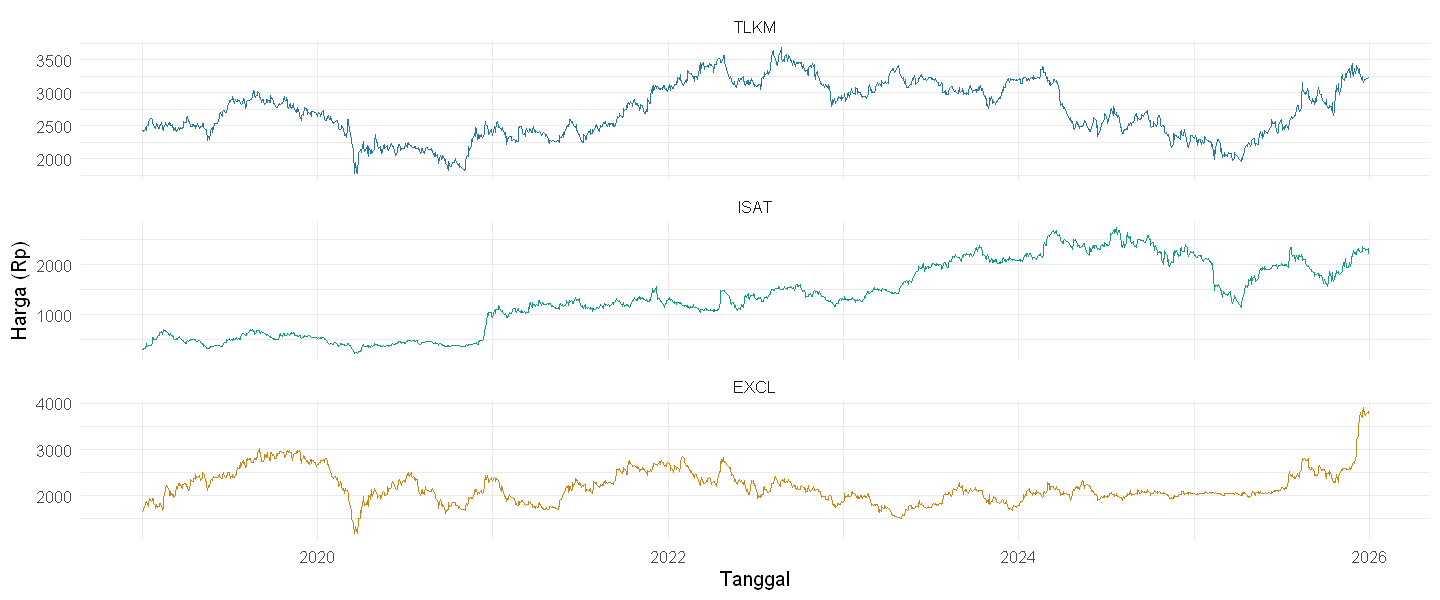

In [6]:
ggplot(long_series(prices), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.4) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Harga (Rp)") +
    theme(legend.position = "none")

### 3.3. Volume Perdagangan

Grafik menampilkan jumlah saham yang diperdagangkan setiap hari dalam jutaan lembar.

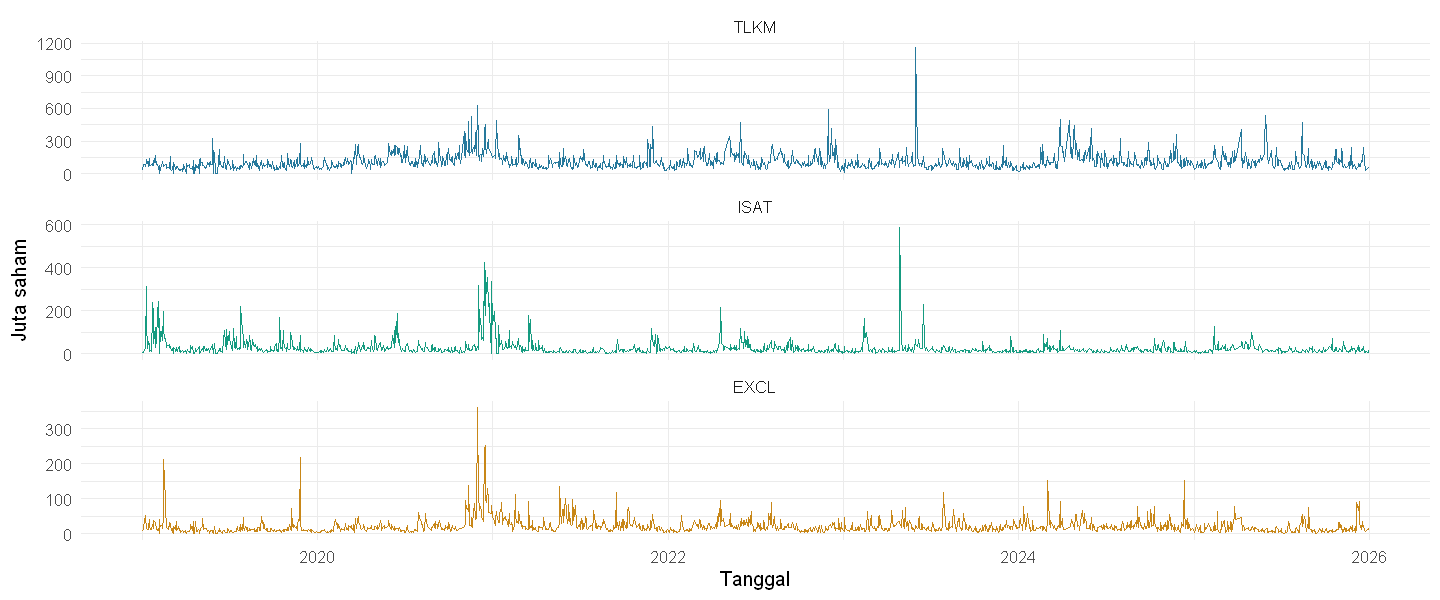

In [7]:
ggplot(long_series(volume), aes(Tanggal, Nilai / 1e6, color = Saham)) +
    geom_line(linewidth = 0.3) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Juta saham") +
    theme(legend.position = "none")

## 4. Perhitungan Simple Return
### 4.1. Simple Return Harian

Simple return mengukur perubahan harga dari satu observasi ke observasi berikutnya.

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}.$$

$P_t$ adalah harga penutupan yang telah disesuaikan pada waktu $t$. Return positif berarti harga naik. [Materi Investasi, Pasar Modal, dan Return](../../Materi/menrisk02%20-%20Investasi%2C%20Pasar%20Modal%2C%20dan%20Return.pdf)

In [8]:
simple_returns_all <- na.omit(ROC(prices, type = "discrete"))
data.frame(Saham = SAHAM, `Jumlah harga` = nrow(prices),
           `Jumlah simple return sebelum pembersihan` = nrow(simple_returns_all),
           check.names = FALSE)

Saham,Jumlah harga,Jumlah simple return sebelum pembersihan
<chr>,<int>,<int>
TLKM,1703,1702
ISAT,1703,1702
EXCL,1703,1702


### 4.2. Pembersihan Return Nol Serentak

Hari ketika return ketiga saham sama-sama nol dikeluarkan. **25 Agustus 2023** tetap disertakan karena ketiga saham mencatat volume perdagangan. Tabel menunjukkan volume dan status setiap tanggal dengan return nol serentak.

In [9]:
tanggal_return <- as.Date(index(simple_returns_all))
semua_nol <- rowSums(coredata(simple_returns_all) == 0) == ncol(simple_returns_all)
hapus <- HAPUS_HARI_NOL & semua_nol & !(tanggal_return %in% TANGGAL_DIPERTAHANKAN)

tanggal_nol <- tanggal_return[semua_nol]
volume_nol <- coredata(volume[tanggal_nol])
zero_return_check <- data.frame(
    Tanggal = tanggal_nol,
    Volume_TLKM = volume_nol[, "TLKM"],
    Volume_ISAT = volume_nol[, "ISAT"],
    Volume_EXCL = volume_nol[, "EXCL"],
    Status = ifelse(hapus[semua_nol], "Dikeluarkan", "Dipertahankan")
)

simple_returns <- simple_returns_all[!hapus, ]
tabel_return <- data.frame(Tanggal = as.Date(index(simple_returns)), coredata(simple_returns))
cat("Jumlah hari return nol serentak yang dikeluarkan =", sum(hapus), "\n")

zero_return_check
data.frame(Saham = SAHAM, Jumlah_return = nrow(simple_returns))
head(tabel_return, 10)
tail(tabel_return)

Jumlah hari return nol serentak yang dikeluarkan = 12 


Tanggal,Volume_TLKM,Volume_ISAT,Volume_EXCL,Status
<date>,<dbl>,<dbl>,<dbl>,<chr>
2019-02-05,0,0,0,Dikeluarkan
2019-03-07,0,0,0,Dikeluarkan
2019-04-03,0,0,0,Dikeluarkan
2019-04-17,0,0,0,Dikeluarkan
2019-04-19,0,0,0,Dikeluarkan
2019-05-01,0,0,0,Dikeluarkan
2019-05-30,0,0,0,Dikeluarkan
2019-06-03,0,0,0,Dikeluarkan
2019-06-04,0,0,0,Dikeluarkan


Saham,Jumlah_return
<chr>,<int>
TLKM,1690
ISAT,1690
EXCL,1690


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-03,0.002681055,0.003039585,0.020202118
2,2019-01-04,-0.008021357,0.045454419,0.009900965
3,2019-01-07,0.016172438,0.023188477,0.049019485
4,2019-01-08,0.007957626,0.022662865,0.023364601
5,2019-01-09,-0.018421172,0.246537473,0.027397258
6,2019-01-10,0.018766880,-0.135555530,0.000000000
7,2019-01-11,0.015789407,0.015424021,-0.022222329
8,2019-01-14,-0.002590663,0.063291303,-0.040908894
9,2019-01-15,0.020779134,0.014285659,0.037914594


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1685,2025-12-19,-0.014450841,0.016736458,0.056910569
1686,2025-12-22,0.017595292,0.004115266,-0.035897436
1687,2025-12-23,0.000000000,-0.008196800,-0.005319149
1688,2025-12-24,-0.002881854,-0.008264437,0.002673797
1689,2025-12-29,0.008670551,0.016666722,0.021333333
1690,2025-12-30,-0.002865339,-0.049180383,-0.020887728


### 4.3. Contoh Perhitungan Simple Return

Contoh ini memakai dua harga berurutan dari saham TLKM dan menampilkan hasilnya dalam desimal dan persen.

In [10]:
saham_contoh <- "TLKM"
previous_price <- as.numeric(prices[1, saham_contoh])
current_price <- as.numeric(prices[2, saham_contoh])
example_return <- current_price / previous_price - 1
data.frame(Saham = saham_contoh,
    `Tanggal sebelumnya` = as.Date(index(prices)[1]), Tanggal = as.Date(index(prices)[2]),
    `Harga sebelumnya` = previous_price, `Harga saat ini` = current_price,
    `Simple return` = example_return, `Simple return (%)` = 100 * example_return,
    check.names = FALSE)


Saham,Tanggal sebelumnya,Tanggal,Harga sebelumnya,Harga saat ini,Simple return,Simple return (%)
<chr>,<date>,<date>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,2019-01-02,2019-01-03,2423.69,2430.188,0.002681055,0.2681055


### 4.4. Statistik Deskriptif Simple Return

Rata-rata return harian 2019–2024 dipakai sebagai perkiraan *expected return*. Variansi menunjukkan seberapa besar return menyebar di sekitar rata-ratanya.

In [11]:
return_estimasi <- simple_returns[index(simple_returns) <= ESTIMASI_AKHIR]
data_return_estimasi <- long_series(return_estimasi)
return_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(return_estimasi),
    Mean = round(colMeans(return_estimasi), 6),
    Variance = round(apply(return_estimasi, 2, var), 6),
    Min = round(apply(return_estimasi, 2, min), 4),
    Max = round(apply(return_estimasi, 2, max), 4),
    Skewness = round(apply(return_estimasi, 2, moments::skewness), 3),
    Kurtosis = round(apply(return_estimasi, 2, moments::kurtosis), 3),
    Zero_Ret = colSums(return_estimasi == 0),
    check.names = FALSE, row.names = NULL
)
return_summary

Saham,N,Mean,Variance,Min,Max,Skewness,Kurtosis,Zero_Ret
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1454,0.000138,0.000337,-0.0696,0.1374,0.615,7.636,121
ISAT,1454,0.001962,0.001216,-0.1356,0.2478,1.724,11.963,115
EXCL,1454,0.000481,0.000687,-0.0925,0.2482,1.202,10.902,153


## 5. Eksplorasi Data Simple Return
### 5.1. Pergerakan Simple Return Harian

Grafik menampilkan perubahan return selama periode estimasi 2019–2024. Bagian 5.6–5.8 memakai data 2019–2025.

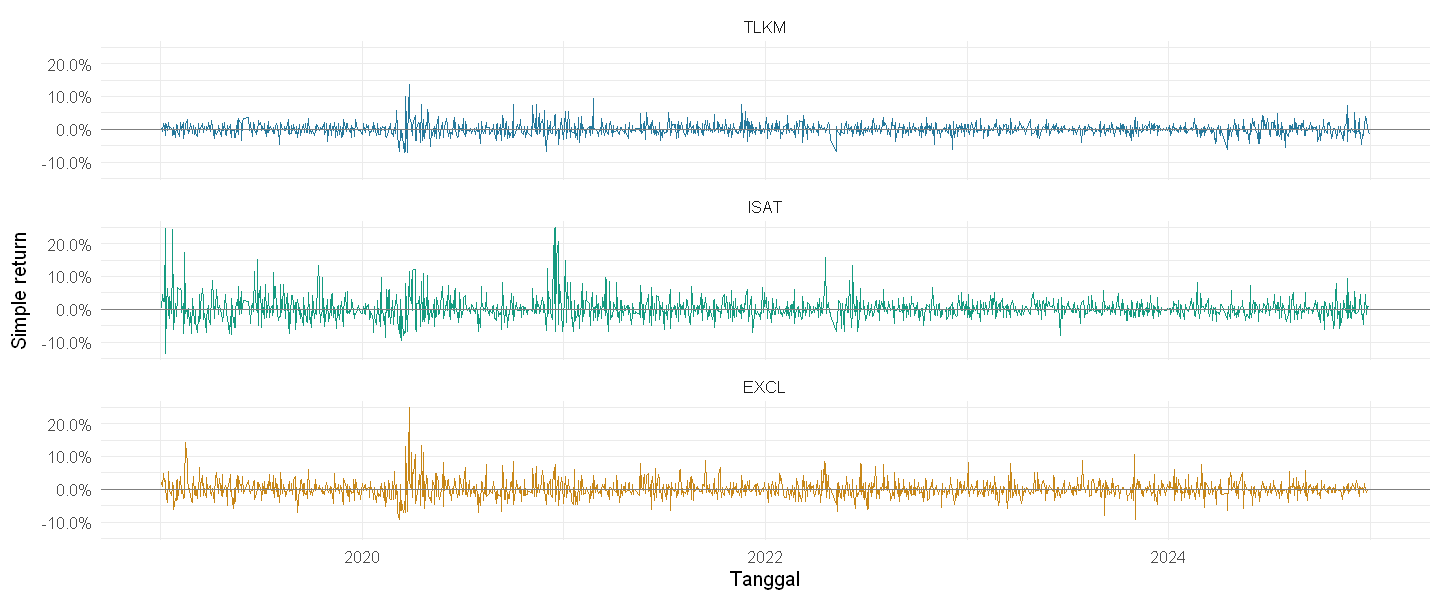

In [12]:
ggplot(data_return_estimasi, aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.3) + geom_hline(yintercept = 0, color = "grey50") +
    facet_wrap(~Saham, ncol = 1) + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Tanggal", y = "Simple return") + theme(legend.position = "none")

### 5.2. Histogram dan Distribusi Normal Pembanding

Garis putus-putus menunjukkan bentuk distribusi normal sebagai pembanding untuk histogram tiap saham.

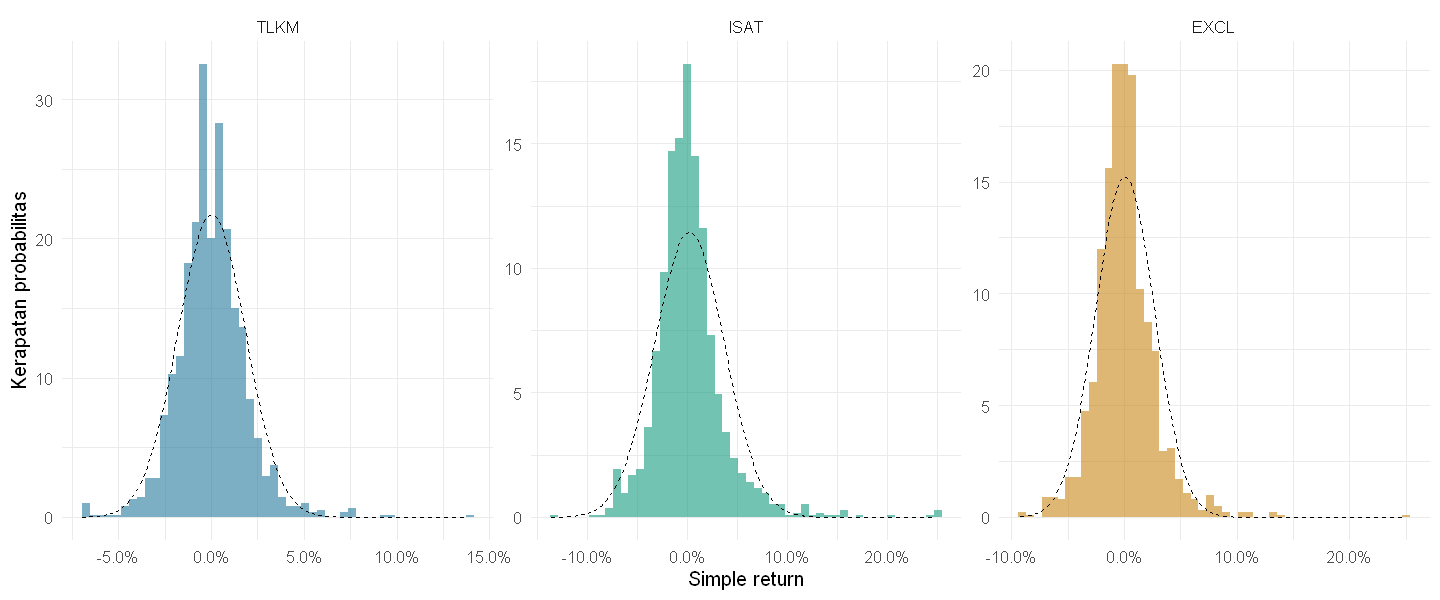

In [13]:
kurva_per_saham <- lapply(SAHAM, function(saham) {
    x <- as.numeric(return_estimasi[, saham])
    grid <- seq(min(x), max(x), length.out = 400)
    data.frame(
        Saham = factor(saham, levels = SAHAM),
        Nilai = grid,
        Densitas = dnorm(grid, mean(x), sd(x))
    )
})
normal_curves <- bind_rows(kurva_per_saham)

ggplot(data_return_estimasi, aes(Nilai)) +
    geom_histogram(aes(y = after_stat(density), fill = Saham), bins = 50, alpha = 0.6) +
    geom_line(data = normal_curves, aes(y = Densitas), linetype = "dashed") +
    facet_wrap(~Saham, scales = "free") + scale_fill_manual(values = COLORS) +
    scale_x_continuous(labels = percent) +
    labs(x = "Simple return", y = "Kerapatan probabilitas") + theme(legend.position = "none")

### 5.3. Boxplot Simple Return

Boxplot menunjukkan median, penyebaran, dan nilai ekstrem. Nilai ekstrem tetap digunakan untuk mengestimasi risiko kerugian.

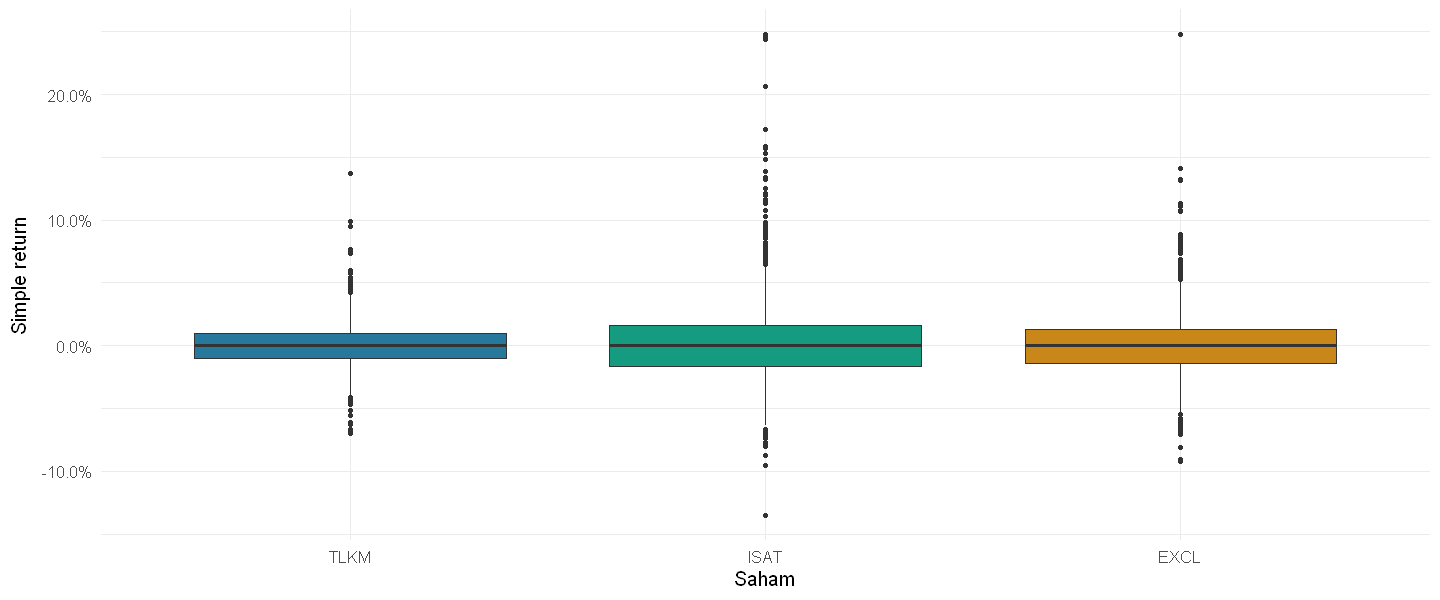

In [14]:
ggplot(data_return_estimasi, aes(Saham, Nilai, fill = Saham)) +
    geom_boxplot(outlier.size = 1) + scale_fill_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Saham", y = "Simple return") + theme(legend.position = "none")

### 5.4. Q–Q Plot terhadap Distribusi Normal

Titik yang menjauh dari garis menunjukkan bagian distribusi return yang berbeda dari pola normal.

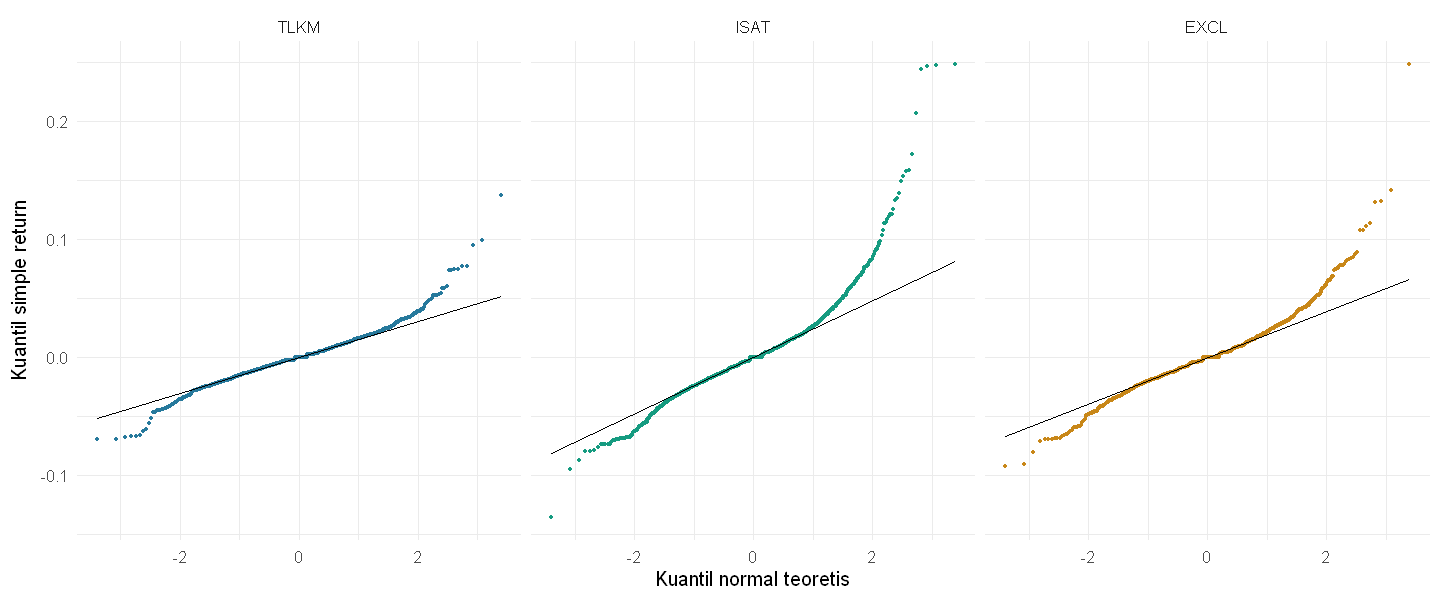

In [15]:
ggplot(data_return_estimasi, aes(sample = Nilai, color = Saham)) +
    stat_qq(size = 0.8) + stat_qq_line(color = "black") +
    facet_wrap(~Saham) + scale_color_manual(values = COLORS) +
    labs(x = "Kuantil normal teoretis", y = "Kuantil simple return") +
    theme(legend.position = "none")

### 5.5. Uji Normalitas Return

Uji Jarque–Bera (JB) dan Kolmogorov–Smirnov (KS) digunakan untuk memeriksa normalitas return 2019–2024. Keputusan pada tabel mengikuti uji JB dengan taraf signifikansi 5%.

In [16]:
normalitas_per_saham <- lapply(SAHAM, function(saham) {
    r <- as.numeric(return_estimasi[, saham])
    jb_p <- moments::jarque.test(r)$p.value
    ks_p <- suppressWarnings(ks.test(r, "pnorm", mean(r), sd(r)))$p.value
    data.frame(
        Saham = saham,
        JB_pvalue = format.pval(jb_p, digits = 3),
        KS_pvalue = format.pval(ks_p, digits = 3),
        Normalitas = ifelse(jb_p < SIGNIFICANCE, "Tolak H0 (tidak normal)", "Gagal menolak H0")
    )
})
norm_tab <- bind_rows(normalitas_per_saham)
norm_tab

Saham,JB_pvalue,KS_pvalue,Normalitas
<chr>,<chr>,<chr>,<chr>
TLKM,<2e-16,7e-05,Tolak H0 (tidak normal)
ISAT,<2e-16,4.77e-14,Tolak H0 (tidak normal)
EXCL,<2e-16,7.48e-10,Tolak H0 (tidak normal)


### 5.6. Volatilitas Return Selama 21 Hari Perdagangan

Grafik memakai standar deviasi return dari 21 observasi terakhir pada setiap tanggal. Nilai yang lebih besar menunjukkan perubahan return yang lebih lebar.

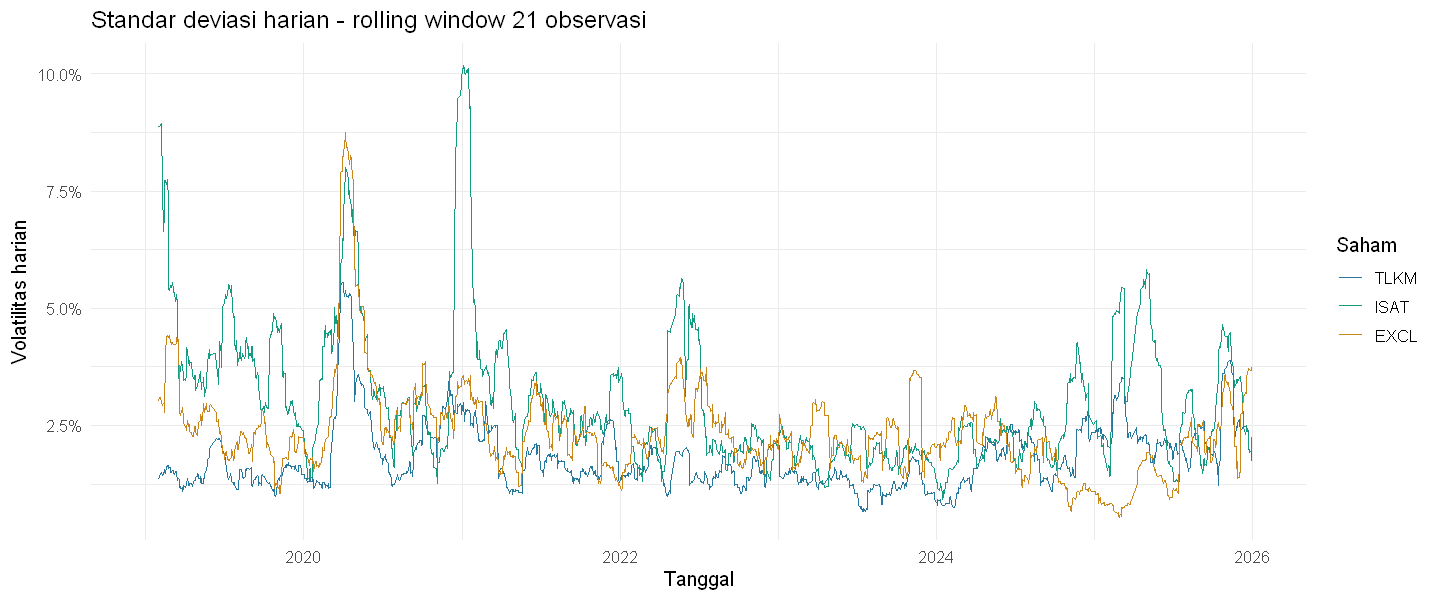

In [17]:
rolling_volatility <- zoo::rollapplyr(simple_returns, WINDOW, sd, fill = NA, by.column = TRUE)
ggplot(long_series(rolling_volatility), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.5, na.rm = TRUE) + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(title = "Standar deviasi harian - rolling window 21 observasi", x = "Tanggal", y = "Volatilitas harian")

### 5.7. Statistik Simple Return per Tahun

Tabel membandingkan rata-rata dan penyebaran return harian dari tahun ke tahun.

In [18]:
return_tahunan <- mutate(long_series(simple_returns), Tahun = as.integer(format(Tanggal, "%Y")))
kelompok_tahunan <- group_by(return_tahunan, Tahun, Saham)
annual_summary <- summarise(
    kelompok_tahunan, N = n(), Mean = mean(Nilai), Variansi = var(Nilai), Std = sd(Nilai),
    Minimum = min(Nilai), Maksimum = max(Nilai), .groups = "drop"
)
annual_summary

Tahun,Saham,N,Mean,Variansi,Std,Minimum,Maksimum
<int>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2019,TLKM,243,5.349101e-04,0.0002147619,0.01465476,-0.04672888,0.03589748
2019,ISAT,243,3.389745e-03,0.0021875132,0.04677086,-0.13555553,0.24653747
2019,EXCL,243,2.222848e-03,0.0006314668,0.02512900,-0.07102281,0.14146347
2020,TLKM,242,-1.977086e-04,0.0007097028,0.02664025,-0.06962023,0.13740458
2020,ISAT,242,3.383815e-03,0.0023328583,0.04829967,-0.09498679,0.24778775
2020,EXCL,242,1.566140e-04,0.0014912180,0.03861629,-0.09090903,0.24822699
2021,TLKM,247,1.174448e-03,0.0003421370,0.01849695,-0.04142021,0.09463731
2021,ISAT,247,1.785248e-03,0.0010556629,0.03249097,-0.06953640,0.14851474
2021,EXCL,247,9.189960e-04,0.0005091017,0.02256328,-0.06513406,0.08856093


### 5.8. Observasi dengan Simple Return Terendah

Tabel menampilkan sepuluh tanggal dengan return terendah untuk setiap saham.

In [19]:
return_per_saham <- group_by(long_series(simple_returns), Saham)
return_terendah <- slice_min(return_per_saham, Nilai, n = 10, with_ties = FALSE)
return_terendah <- mutate(ungroup(return_terendah), `Simple return (%)` = 100 * Nilai)
extreme_negative_returns <- rename(return_terendah, `Simple return` = Nilai)
extreme_negative_returns

Tanggal,Saham,Simple return,Simple return (%)
<date>,<fct>,<dbl>,<dbl>
2020-03-17,TLKM,-0.06962023,-6.962023
2020-03-23,TLKM,-0.06944431,-6.944431
2020-03-19,TLKM,-0.06761562,-6.761562
2022-05-09,TLKM,-0.06709949,-6.709949
2020-03-09,TLKM,-0.06666656,-6.666656
2020-11-30,TLKM,-0.06647402,-6.647402
2022-12-06,TLKM,-0.06250002,-6.250002
2024-04-16,TLKM,-0.06122459,-6.122459
2025-02-10,TLKM,-0.05791514,-5.791514


## 6. Metode Estimasi Value at Risk
### 6.1. VaR dan Block Maxima

VaR memperkirakan ambang kerugian pada tingkat kepercayaan tertentu. VaR harian 95% sebesar 3% berarti model memperkirakan kerugian melebihi 3% pada sekitar 5% hari perdagangan.

Kerugian dihitung sebagai negatif return ($L_t=-r_t$). Metode Block Maxima mengambil kerugian terbesar dari setiap blok lima observasi berurutan. Blok tidak saling tumpang tindih. Blok terakhir dikeluarkan jika observasinya kurang dari lima. [Najamuddin dkk. (2024)](https://doi.org/10.30598/barekengvol18iss2pp0695-0706)

### 6.2. Distribusi GEV dan VaR Harian

Distribusi GEV dipasang pada maksimum kerugian tiap blok dengan metode kemungkinan maksimum. Jika kerugian harian diasumsikan independen dan mengikuti distribusi yang sama, VaR harian pada tingkat kepercayaan $c$ dihitung dari kuantil GEV pada peluang $c^m$.

$$q_c=G_m^{-1}(c^m), \qquad m=5.$$

### 6.3. VaR dalam Persen dan Rupiah

VaR desimal dikalikan 100 agar terbaca dalam persen, atau dikalikan Rp1 miliar untuk memperoleh nilai kerugian dalam rupiah per saham.

In [20]:
# Block maxima dari LOSS (ekor kerugian); blok akhir yang tidak penuh dibuang.
block_maxima <- function(loss, m) {
    n_lengkap <- length(loss) %/% m * m
    blok <- matrix(head(loss, n_lengkap), nrow = m)
    apply(blok, 2, max)
}

# Estimasi GEV (MLE) memakai evd::fgev; retry tanpa Hessian bila SE gagal dihitung.
fit_gev <- function(bm) {
    tryCatch(
        evd::fgev(bm, std.err = TRUE),
        error = function(e) evd::fgev(bm, std.err = FALSE)
    )
}

# VaR harian dari GEV blok:
# P(loss harian <= VaR) = level  =>  P(max blok <= VaR) = level^m
var_gev <- function(par, m, level) {
    evd::qgev(level^m, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
}

## 7. Estimasi Value at Risk
### 7.1. Periode Estimasi dan Periode Backtesting

Model memakai return 2019–2024. VaR hasil estimasi digunakan sebagai ambang tetap sepanjang periode backtesting tahun 2025.

In [21]:
tanggal <- index(simple_returns)
return_backtesting <- simple_returns[tanggal >= BACKTESTING_AWAL & tanggal <= BACKTESTING_AKHIR]
kerugian_estimasi <- -return_estimasi
kerugian_backtesting <- -return_backtesting
split_summary <- data.frame(
    Periode = c("Estimasi", "Backtesting"),
    `Awal return` = as.Date(c(index(return_estimasi)[1], index(return_backtesting)[1])),
    `Akhir return` = as.Date(c(tail(index(return_estimasi), 1), tail(index(return_backtesting), 1))),
    `N return per saham` = c(nrow(return_estimasi), nrow(return_backtesting)), check.names = FALSE
)
split_summary

Periode,Awal return,Akhir return,N return per saham
<chr>,<date>,<date>,<int>
Estimasi,2019-01-03,2024-12-30,1454
Backtesting,2025-01-02,2025-12-30,236


### 7.2. Estimasi GEV dan Uji Gumbel

Model GEV memiliki parameter lokasi, skala, dan bentuk. Uji rasio kemungkinan membandingkannya dengan model Gumbel, yang menetapkan parameter bentuk $\xi=0$.

In [22]:
fits <- setNames(lapply(SAHAM, function(saham) {
    kerugian <- as.numeric(kerugian_estimasi[, saham])
    bm <- block_maxima(kerugian, BLOCK_SIZE)
    list(bm = bm, fit = fit_gev(bm))
}), SAHAM)

parameter_per_saham <- lapply(SAHAM, function(saham) {
    bm <- fits[[saham]]$bm
    gev <- fits[[saham]]$fit
    parameter <- gev$estimate
    shape <- parameter[["shape"]]
    se_shape <- gev$std.err[["shape"]]
    if (is.null(se_shape)) se_shape <- NA_real_
    ci_shape <- shape + c(-1, 1) * 1.96 * se_shape

    tipe_ekor <- if (isTRUE(ci_shape[1] > 0)) {
        "Heavy tail (Frechet)"
    } else if (isTRUE(ci_shape[2] < 0)) {
        "Ekor pendek (Weibull)"
    } else {
        "xi tidak signifikan beda dari 0"
    }

    gumbel <- tryCatch(
        evd::fgev(bm, shape = 0, std.err = FALSE),
        error = function(e) NULL
    )
    p_gumbel <- if (is.null(gumbel)) NA_real_ else {
        1 - pchisq(gumbel$deviance - gev$deviance, df = 1)
    }

    data.frame(
        Saham = saham, Jml_Blok = length(bm),
        Location = round(parameter[["loc"]], 5),
        Scale = round(parameter[["scale"]], 5),
        Shape = round(shape, 4),
        Shape_CI95 = sprintf("[%.3f ; %.3f]", ci_shape[1], ci_shape[2]),
        LR_Gumbel_p = round(p_gumbel, 4),
        Tipe_Ekor = tipe_ekor,
        Konvergensi = gev$convergence
    )
})
param_tab <- bind_rows(parameter_per_saham)
param_tab

Saham,Jml_Blok,Location,Scale,Shape,Shape_CI95,LR_Gumbel_p,Tipe_Ekor,Konvergensi
<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>
TLKM,290,0.01375,0.00970,-0.0001,[-0.064 ; 0.064],0.9149,xi tidak signifikan beda dari 0,successful
ISAT,290,0.02095,0.01650,-0.0258,[-0.097 ; 0.046],0.4948,xi tidak signifikan beda dari 0,successful
EXCL,290,0.01834,0.01335,0.0000,[-0.081 ; 0.081],0.9974,xi tidak signifikan beda dari 0,successful


### 7.3. Grafik Kesesuaian GEV

Grafik membantu melihat seberapa dekat distribusi GEV dengan data maksimum kerugian.

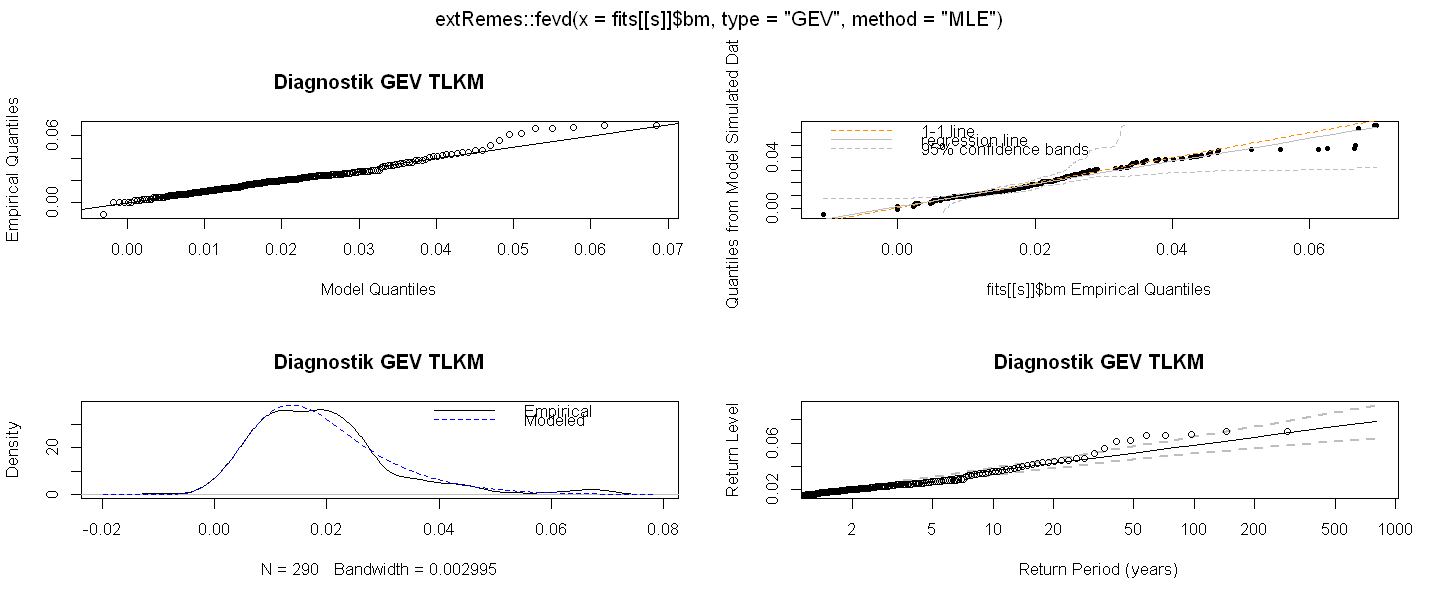

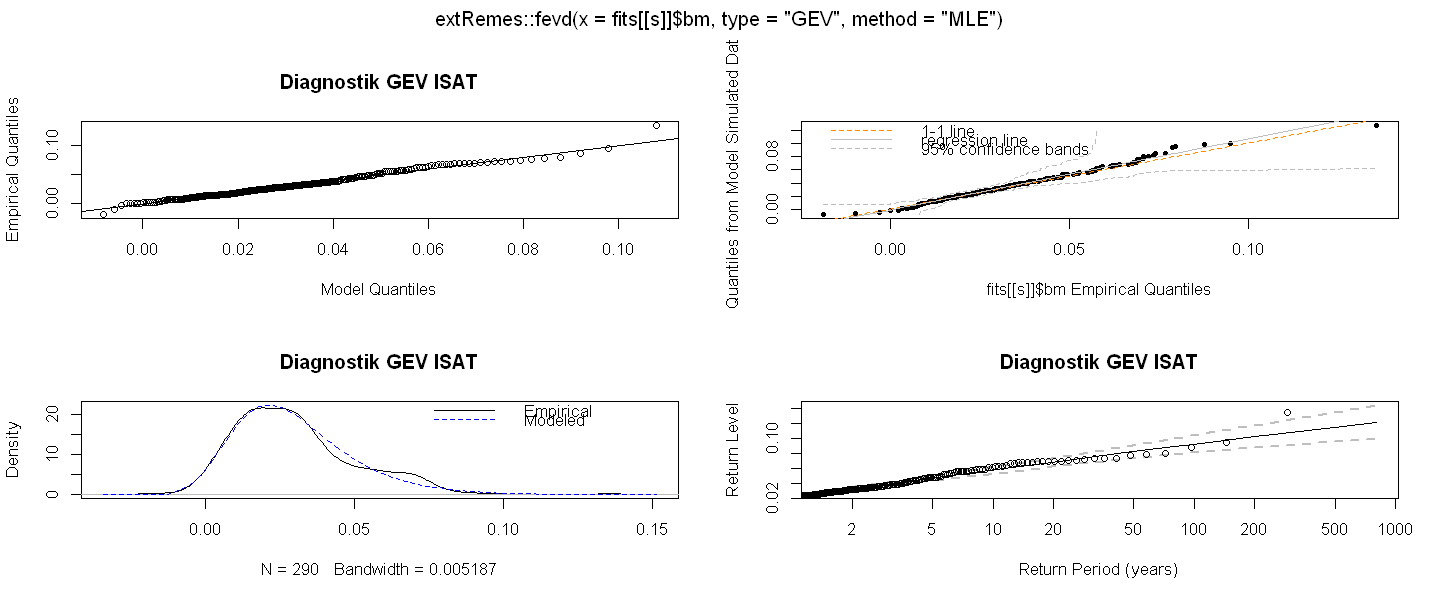

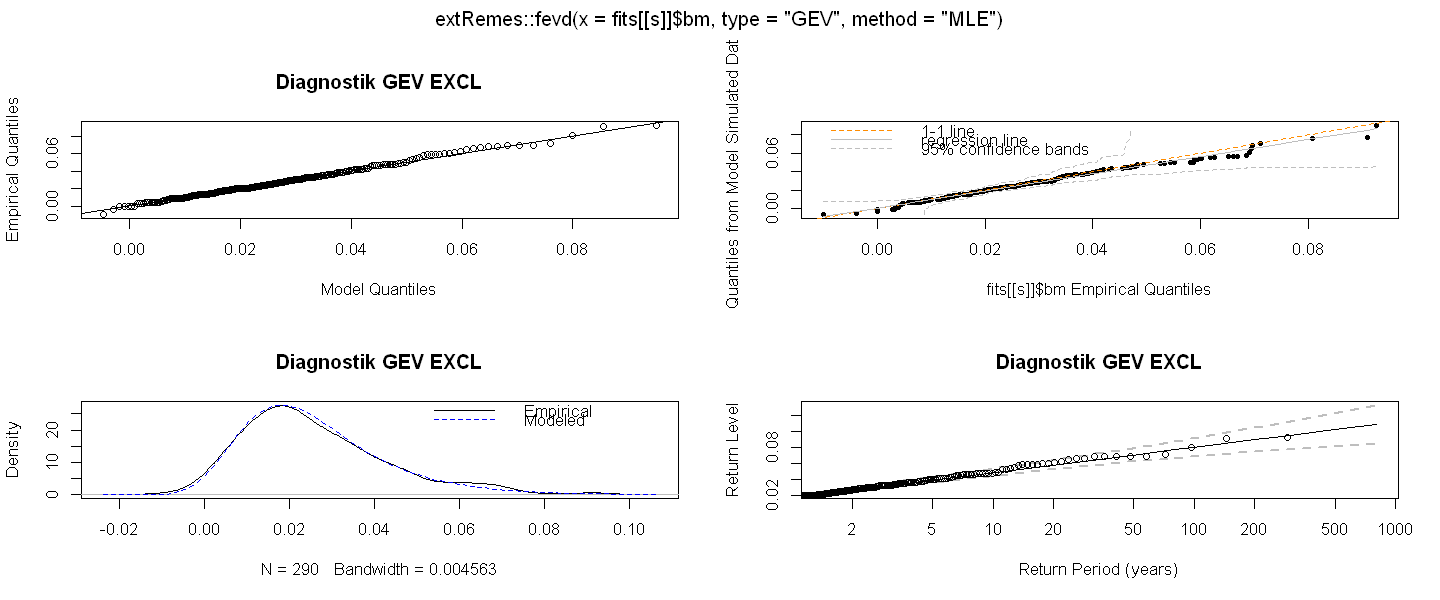

In [ ]:
options(repr.plot.bg = "white")

for (s in SAHAM) {
    par(bg = "white")
    diagnostic_fit <- extRemes::fevd(fits[[s]]$bm, type = "GEV", method = "MLE")
    plot(diagnostic_fit, main = paste("Diagnostik GEV", s))
}

### 7.4. Uji Kesesuaian GEV dengan Kolmogorov–Smirnov

Uji KS membandingkan distribusi maksimum kerugian dalam data dengan distribusi GEV hasil estimasi. Hasil uji dibaca bersama grafik kesesuaian.

In [24]:
kesesuaian_per_saham <- lapply(SAHAM, function(saham) {
    bm <- fits[[saham]]$bm
    par <- fits[[saham]]$fit$estimate
    ks_gev <- suppressWarnings(
        ks.test(bm, evd::pgev, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
    )
    data.frame(
        Saham = saham,
        D_KS = round(as.numeric(ks_gev$statistic), 4),
        P_Value = round(ks_gev$p.value, 4),
        Keputusan = ifelse(ks_gev$p.value > SIGNIFICANCE, "Gagal menolak H0", "Tolak H0")
    )
})
gof_tab <- bind_rows(kesesuaian_per_saham)
gof_tab

Saham,D_KS,P_Value,Keputusan
<chr>,<dbl>,<dbl>,<chr>
TLKM,0.0609,0.2325,Gagal menolak H0
ISAT,0.0344,0.8825,Gagal menolak H0
EXCL,0.0350,0.8692,Gagal menolak H0


### 7.5. VaR Harian pada Tingkat Kepercayaan 95% dan 99%

Tabel membandingkan ambang kerugian harian tiap saham dalam persen dan rupiah.

In [25]:
var_per_saham <- lapply(SAHAM, function(saham) {
    par <- fits[[saham]]$fit$estimate
    data.frame(
        Saham = saham,
        Level = CONFIDENCE_LEVELS,
        VaR = var_gev(par, BLOCK_SIZE, CONFIDENCE_LEVELS)
    )
})
nilai_var <- bind_rows(var_per_saham)

var_tab <- transmute(
    nilai_var, Saham, Level,
    VaR_BM = round(VaR, 5),
    Persentase_Risiko = paste0(round(VaR * 100, 2), "%"),
    Estimasi_Rugi_Rp = format(
        round(VaR * INVESTMENT), big.mark = ".", decimal.mark = ",",
        scientific = FALSE, trim = TRUE
    )
)
var_tab

Saham,Level,VaR_BM,Persentase_Risiko,Estimasi_Rugi_Rp
<chr>,<dbl>,<dbl>,<chr>,<chr>
TLKM,0.95,0.02695,2.69%,26.946.565
TLKM,0.99,0.04276,4.28%,42.756.648
ISAT,0.95,0.04302,4.3%,43.016.422
ISAT,0.99,0.06845,6.84%,68.446.680
EXCL,0.95,0.03650,3.65%,36.502.599
EXCL,0.99,0.05826,5.83%,58.262.181


### 7.6. Pengaruh Panjang Blok terhadap VaR

VaR juga dihitung dengan blok 10 dan 21 observasi untuk melihat pengaruh panjang blok terhadap hasil. Blok yang lebih panjang menghasilkan lebih sedikit maksimum kerugian.

In [26]:
block_sensitivity <- data.frame()
for (size in c(5, 10, 21)) {
    for (s in SAHAM) {
        bm  <- block_maxima(as.numeric(kerugian_estimasi[, s]), size)
        fit <- fit_gev(bm)
        q   <- var_gev(fit$estimate, size, CONFIDENCE_LEVELS)
        block_sensitivity <- rbind(block_sensitivity, data.frame(
            Saham = s, Panjang_blok = size, Jumlah_blok = length(bm),
            Kepercayaan = CONFIDENCE_LEVELS, VaR_persen = 100 * q,
            check.names = FALSE
        ))
    }
}
block_sensitivity

Saham,Panjang_blok,Jumlah_blok,Kepercayaan,VaR_persen
<chr>,<dbl>,<int>,<dbl>,<dbl>
TLKM,5,290,0.95,2.694656
TLKM,5,290,0.99,4.275665
ISAT,5,290,0.95,4.301642
ISAT,5,290,0.99,6.844668
EXCL,5,290,0.95,3.650260
EXCL,5,290,0.99,5.826218
TLKM,10,145,0.95,2.562403
TLKM,10,145,0.99,4.234148
ISAT,10,145,0.95,4.059402


## 8. Backtesting dengan Uji Kupiec dan Christoffersen
### 8.1. Pemeriksaan Exception VaR

*Exception* terjadi saat kerugian aktual lebih besar dari VaR. Uji Kupiec memeriksa apakah jumlah *exception* sesuai dengan tingkat kepercayaan. Uji Christoffersen memeriksa apakah *exception* cenderung berurutan. Uji gabungan atau *conditional coverage* mempertimbangkan keduanya. Taraf signifikansi yang digunakan adalah 5%. [Kupiec (1995)](https://fedinprint.org/item/fedgfe/34596/original) · [Christoffersen (1998)](https://doi.org/10.2307/2527341)

Ketiga uji dihitung dengan paket R `tstests`. Tabel menampilkan NA jika paket tidak bisa menghitung uji karena urutan data hanya memuat satu jenis kejadian. [Dokumentasi tstests](https://cran.r-project.org/web/packages/tstests/vignettes/tstest_introduction.html)

In [27]:
bt_tab <- data.frame()
backtest_daily <- data.frame()
tanggal_backtesting <- as.Date(index(kerugian_backtesting))
jumlah_hari <- length(tanggal_backtesting)

for (i in seq_len(nrow(nilai_var))) {
    saham <- nilai_var$Saham[i]
    level <- nilai_var$Level[i]
    ambang_var <- nilai_var$VaR[i]
    kerugian <- as.numeric(kerugian_backtesting[, saham])
    exception <- as.integer(kerugian > ambang_var)
    alpha <- 1 - level

    statistik <- p_value <- rep(NA_real_, 3)
    # Paket memerlukan status 0 dan 1 pada kedua sisi tabel transisi.
    if (length(unique(head(exception, -1))) == 2 &&
        length(unique(tail(exception, -1))) == 2) {
        hasil <- withCallingHandlers(
            tstests::var_cp_test(
                actual = -kerugian,
                forecast = rep(-ambang_var, jumlah_hari),
                alpha = alpha
            ),
            warning = function(w) {
                if (grepl("unable to calculate duration test CP (D)", conditionMessage(w), fixed = TRUE)) {
                    invokeRestart("muffleWarning")
                }
            }
        )
        statistik <- hasil$table$Statistic[1:3]
        p_value <- hasil$p_value[1:3]
    }

    bt_tab <- rbind(bt_tab, data.frame(
        Saham = saham, Level = level, N_backtesting = jumlah_hari,
        Exception = sum(exception), Expected = round(jumlah_hari * alpha, 1),
        Exception_Rate = round(mean(exception), 4),
        Kupiec_LR = round(statistik[1], 3), Kupiec_p = round(p_value[1], 4),
        Christ_LR = round(statistik[2], 3), Christ_p = round(p_value[2], 4),
        CC_LR = round(statistik[3], 3), CC_p = round(p_value[3], 4),
        Kesimpulan = ifelse(p_value[3] > SIGNIFICANCE, "Valid", "Tidak valid")
    ))
    backtest_daily <- rbind(backtest_daily, data.frame(
        Tanggal = tanggal_backtesting, Saham = saham,
        Kepercayaan = level, Kerugian = kerugian,
        VaR_harian = ambang_var, Exception = exception
    ))
}
bt_tab

Saham,Level,N_backtesting,Exception,Expected,Exception_Rate,Kupiec_LR,Kupiec_p,Christ_LR,Christ_p,CC_LR,CC_p,Kesimpulan
<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
TLKM,0.95,236,18,11.8,0.0763,2.975,0.0846,0.133,0.7154,3.108,0.2114,Valid
TLKM,0.99,236,6,2.4,0.0254,3.974,0.0462,2.320,0.1277,6.294,0.0430,Tidak valid
ISAT,0.95,236,16,11.8,0.0678,1.423,0.2329,0.871,0.3506,2.294,0.3176,Valid
ISAT,0.99,236,4,2.4,0.0169,0.953,0.3291,3.995,0.0456,4.948,0.0842,Valid
EXCL,0.95,236,5,11.8,0.0212,5.218,0.0224,0.217,0.6410,5.435,0.0660,Valid
EXCL,0.99,236,1,2.4,0.0042,1.011,0.3148,0.009,0.9263,1.019,0.6008,Valid


### 8.2. Grafik Exception VaR Tahun 2025

Garis putus-putus menunjukkan ambang VaR. Titik merah menandai hari ketika kerugian aktual melampaui ambang tersebut.

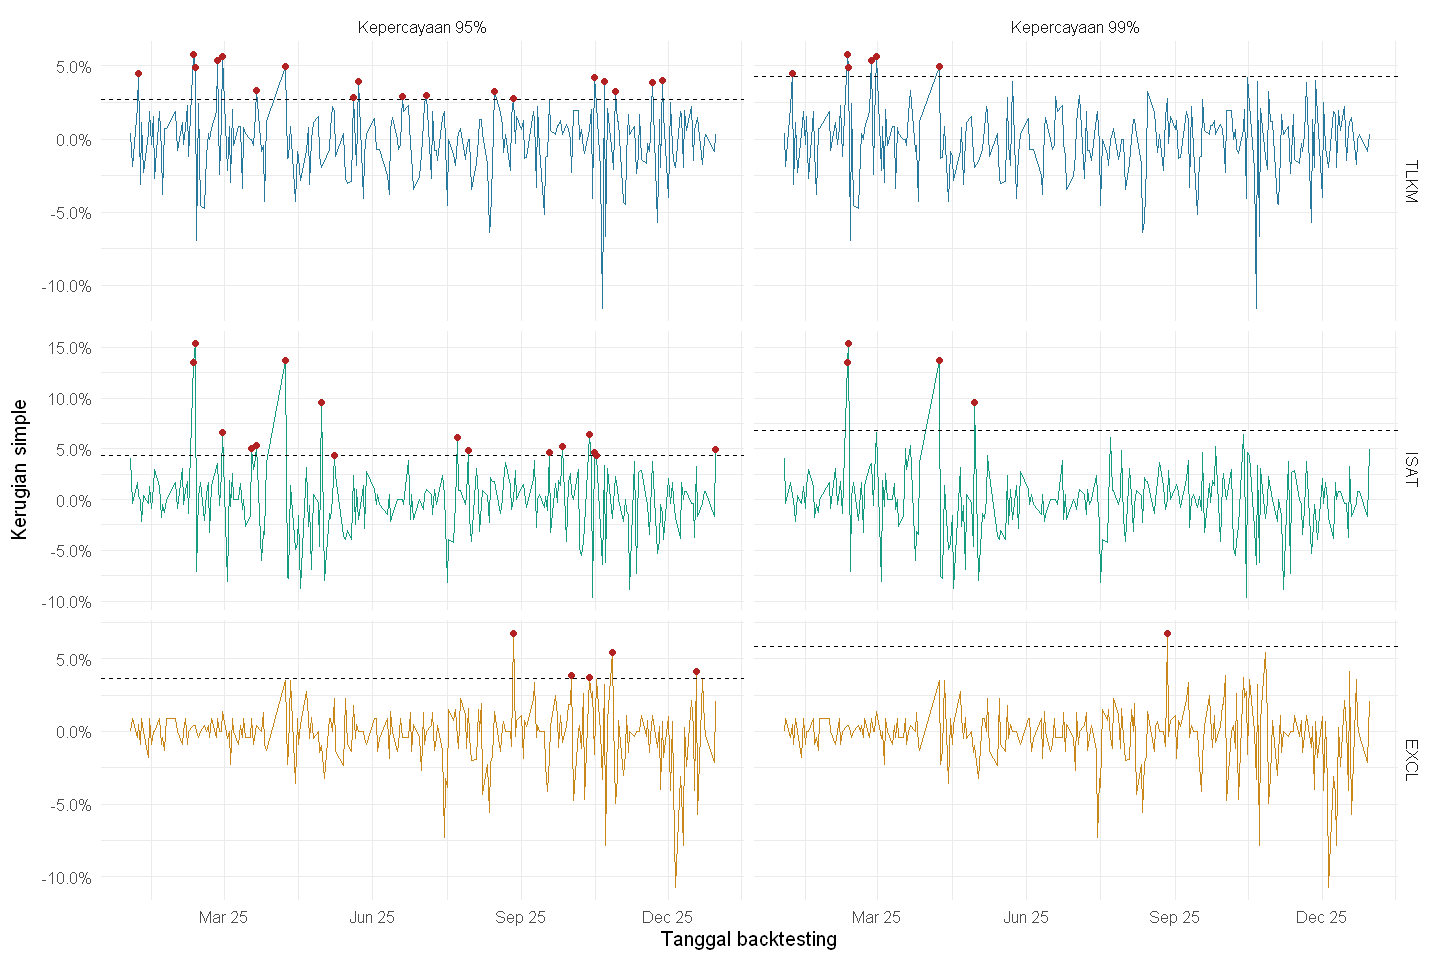

In [28]:
options(repr.plot.height = 8)

plot_daily <- mutate(
    backtest_daily,
    Saham = factor(Saham, levels = SAHAM),
    Tingkat = paste0("Kepercayaan ", 100 * Kepercayaan, "%")
)
thresholds <- distinct(plot_daily, Saham, Tingkat, VaR_harian)
ggplot(plot_daily, aes(Tanggal, Kerugian, color = Saham)) +
    geom_line(linewidth = 0.35) +
    geom_hline(data = thresholds, aes(yintercept = VaR_harian),
               color = "black", linetype = "dashed") +
    geom_point(data = filter(plot_daily, Exception == 1), color = "firebrick", size = 1.6) +
    facet_grid(Saham ~ Tingkat, scales = "free_y") + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    scale_x_date(date_breaks = "3 months", date_labels = "%b %y") +
    labs(x = "Tanggal backtesting", y = "Kerugian simple") + theme(legend.position = "none")

## 9. Referensi

1. Najamuddin, F. F., Herdiani, E. T., & Jaya, A. K. (2024). *Value at Risk Estimation Using Extreme Value Theory Approach in Indonesia Stock Exchange*. BAREKENG, 18(2), 695–706. https://doi.org/10.30598/barekengvol18iss2pp0695-0706
2. Ayuni, N., Rizki, S. W., & Perdana, H. (2020). *Analisis Risiko Portofolio LQ45 Menggunakan Pendekatan Value at Risk Block Maxima-Generalized Extreme Value*. Bimaster, 9(2). https://doi.org/10.26418/bbimst.v9i2.39914
3. Ambarsari, A., Sudarno, & Tarno. (2016). *Perbandingan Pendekatan Generalized Extreme Value dan Generalized Pareto Distribution untuk Perhitungan Value at Risk pada Portofolio Saham*. Jurnal Gaussian, 5(3), 361–371. https://doi.org/10.14710/j.gauss.5.3.361-371
4. Kupiec, P. H. (1995). *Techniques for Verifying the Accuracy of Risk Measurement Models*. Finance and Economics Discussion Series 95-24, Board of Governors of the Federal Reserve System. https://fedinprint.org/item/fedgfe/34596/original
5. Simpson, E. S., & Northrop, P. J. (2026). *Accounting for Missing Data When Modelling Block Maxima*. Environmetrics, 37(2), e70075. https://doi.org/10.1002/env.70075
6. SciPy. *scipy.stats.genextreme*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.genextreme.html
7. quantmod. *getSymbols*, *Ad*, *Vo*, dan *ROC*. https://cran.r-project.org/web/packages/quantmod/quantmod.pdf

PDF artikel yang tersedia dan catatan penelusuran tersimpan di folder `Referensi/`. Sumber profil emiten dicantumkan pada bagian deskripsi data.